# CSCI 3003 - Data Visualization
## Lab 6B: A Regression Workflow with scikit-learn
**Name:** Steve Tatsiguia  
**Date:** 2026-10-08  
**Version:** Student notebook

## Learning objectives

- Use the estimator sequence `create → fit → predict → evaluate` 
- Construct two-dimensional `X` and one-dimensional `y`
- Interpret coefficients; visualize predictions and residuals
- Calculate in-sample MAE, RMSE, and R-squared;
- Verify the fit against statsmodels

## Scope
All prepared observations are used for both fitting and evaluation. Every metric is therefore an **in-sample description**, not evidence of performance on unseen penguins. Lab 7 introduces training and test data.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
penguin_file = Path("penguins.csv")
penguins = pd.read_csv(penguin_file)
model_data = penguins.loc[:, ["flipper_length_mm", "body_mass_g", "species"]].dropna(
    subset=["flipper_length_mm", "body_mass_g"]
)
print(penguin_file.exists(), model_data.shape)
model_data.head()

True (342, 3)


,flipper_length_mm,body_mass_g,species
0,181.0,3750.0,Adelie
1,186.0,3800.0,Adelie
2,195.0,3250.0,Adelie
4,193.0,3450.0,Adelie
5,190.0,3650.0,Adelie


**Question 1:** Suppose you want to use flipper length to predict body mass. Identify the predictor, response, units, and meaning of one row.

**Answer:** The predictor is flipper length, measured in millimeters, and the response is body mass, measured in grams. Each row represents one penguin and includes its flipper length, body mass, and species.

## I. Define X and y
`X` is a two-dimensional feature table. `y` is a one-dimensional response. Double brackets preserve a one-column DataFrame.

In [3]:
X = model_data[["flipper_length_mm"]]
y = model_data["body_mass_g"]
print("X shape:", X.shape, "y shape:", y.shape)

X shape: (342, 1) y shape: (342,)


**Question 2:** Explain why X has two dimensions X and why y has one dimension.

**Answer:** X has two dimensions because scikit-learn expects a table with rows for penguins and columns for predictors. Even with only one predictor, its shape is (342, 1). y has one dimension because it contains a single body mass value for each penguin, giving it a shape of (342,)

## II. Create, fit, and inspect the estimator

In [4]:
sklearn_model = LinearRegression()
sklearn_model.fit(X, y)
print("Intercept:", sklearn_model.intercept_)
print("Slope:", sklearn_model.coef_[0])

Intercept: -5780.831358077063
Slope: 49.68556640610009


The trailing underscore marks an attribute learned during `.fit()`.

**Question 3:** Write the equation; interpret its slope; explain why the intercept is not substantively useful.

**Answer:** The equation is predicted body mass = −5780.83 + 49.69 × flipper length.
For each additional millimeter of flipper length, the model predicts about 49.69 grams more body mass. The intercept predicts a body mass of −5780.83 grams when flipper length is zero. This is not useful because penguins cannot have a zero-length flipper or negative body mass, and zero is outside the observed range.

## III. Predict and calculate residuals
`.predict()` requires the same feature-table structure used during fitting.

In [5]:
predicted = sklearn_model.predict(X)
results = model_data.assign(predicted_body_mass_g=predicted, residual_g=y - predicted)
results.head()

,flipper_length_mm,body_mass_g,species,predicted_body_mass_g,residual_g
0,181.0,3750.0,Adelie,3212.256161,537.743839
1,186.0,3800.0,Adelie,3460.683993,339.316007
2,195.0,3250.0,Adelie,3907.854091,-657.854091
4,193.0,3450.0,Adelie,3808.482958,-358.482958
5,190.0,3650.0,Adelie,3659.426259,-9.426259


In [6]:
new_penguins = pd.DataFrame({"flipper_length_mm": [180, 200, 220]})
new_penguins.assign(predicted_body_mass_g=sklearn_model.predict(new_penguins))

,flipper_length_mm,predicted_body_mass_g
0,180,3162.570595
1,200,4156.281923
2,220,5149.993251


**Question 4:** Verify residual of the first observation and interpret its sign.

**Answer:** The first penguin’s residual is 3750 − 3212.26 = 537.74 grams. The positive residual means the penguin weighs about 538 grams more than predicted, so the model underestimated its body mass.

In [7]:
new_penguins.loc[0]

flipper_length_mm    180
Name: 0, dtype: int64

## IV. Visualize predictions

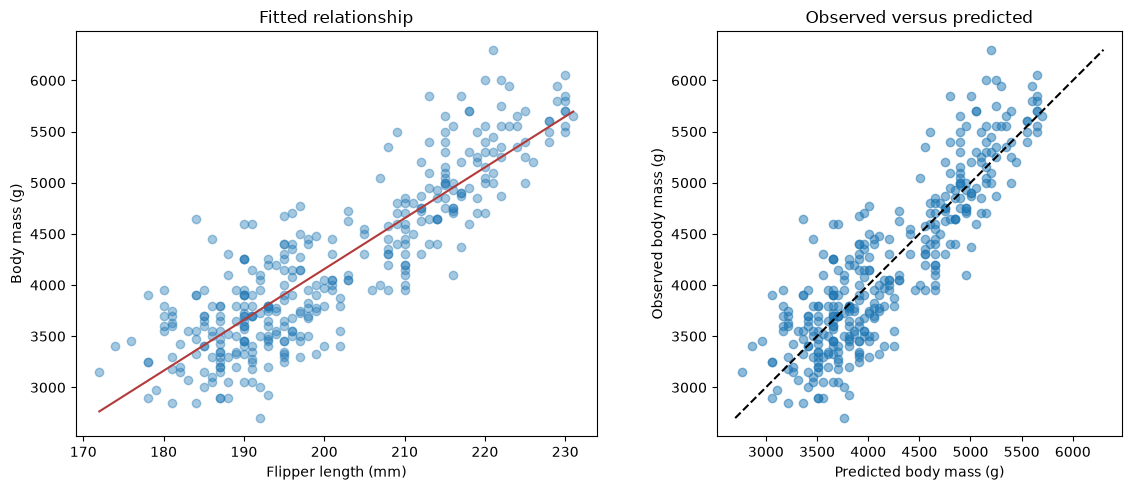

In [8]:
line = pd.DataFrame(
    {
        "flipper_length_mm": np.linspace(
            X.flipper_length_mm.min(), X.flipper_length_mm.max(), 100
        )
    }
)
line["prediction"] = sklearn_model.predict(line)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X.flipper_length_mm, y, alpha=0.4)
axes[0].plot(line.flipper_length_mm, line.prediction, color="#B33A3A")
axes[0].set(
    title="Fitted relationship", xlabel="Flipper length (mm)", ylabel="Body mass (g)"
)
lo = min(results.predicted_body_mass_g.min(), results.body_mass_g.min())
hi = max(results.predicted_body_mass_g.max(), results.body_mass_g.max())
axes[1].scatter(results.predicted_body_mass_g, results.body_mass_g, alpha=0.5)
axes[1].plot([lo, hi], [lo, hi], "k--")
axes[1].set_aspect("equal", adjustable="box")
axes[1].set(
    title="Observed versus predicted",
    xlabel="Predicted body mass (g)",
    ylabel="Observed body mass (g)",
)
fig.tight_layout()
plt.show()

**Question 5:** What does a point above the identity line mean? Why use equal scales?

**Answer:** A point above the identity line means the penguin’s actual body mass is greater than its predicted body mass, so the model underestimated its weight. Equal scales make one gram cover the same distance on both axes, making prediction errors easier to judge accurately.

## V. Evaluate in-sample fit

MAE is average absolute residual size.  
RMSE gives more influence to large residuals. Both use response units. R-squared summarizes variation described in the fitting data.

In [9]:
mae = mean_absolute_error(y, predicted)
rmse = mean_squared_error(y, predicted) ** 0.5
r_squared = r2_score(y, predicted)
pd.Series({"MAE (g)": mae, "RMSE (g)": rmse, "R-squared": r_squared})

MAE (g)      313.001836
RMSE (g)     393.123627
R-squared      0.758993
dtype: float64

**Question 6:** Interpret MAE and RMSE. What can their gap reveal? Why do these metrics not establish future performance?

**Answer:** The MAE is about 313 grams, meaning predictions differ from actual body mass by 313 grams on average. The RMSE is about 393 grams and gives more weight to larger errors. Its higher value suggests some penguins have relatively large prediction errors. These metrics do not establish future performance because the model was evaluated using the same penguins it was trained on, rather than new data.

## VI. Residual visualization

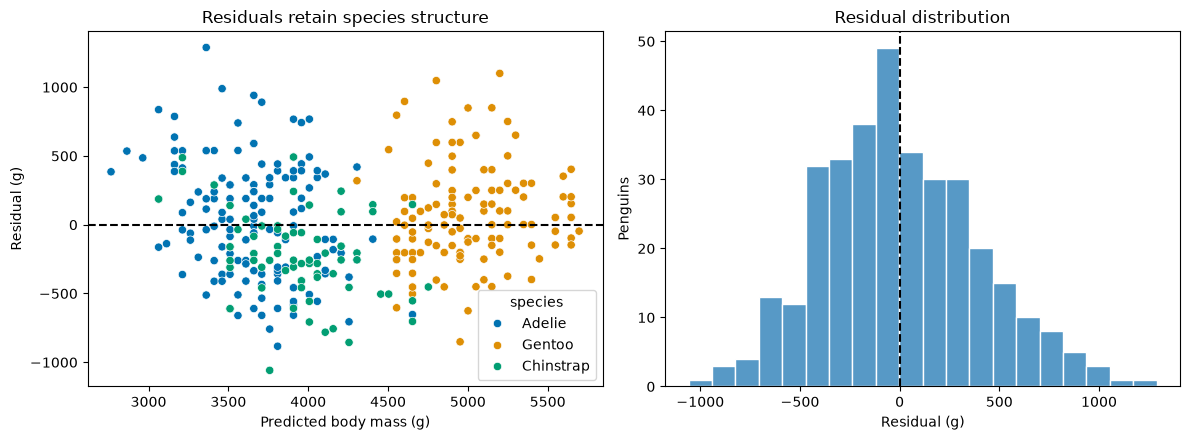

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(
    data=results,
    x="predicted_body_mass_g",
    y="residual_g",
    hue="species",
    palette="colorblind",
    ax=axes[0],
)
axes[0].axhline(0, color="black", ls="--")
axes[0].set(
    title="Residuals retain species structure",
    xlabel="Predicted body mass (g)",
    ylabel="Residual (g)",
)
sns.histplot(data=results, x="residual_g", bins=20, edgecolor="white", ax=axes[1])
axes[1].axvline(0, color="black", ls="--")
axes[1].set(title="Residual distribution", xlabel="Residual (g)", ylabel="Penguins")
fig.tight_layout()
plt.show()

**Question 7:** What group pattern remains that MAE and RMSE hide?

**Answer:** The residual plot shows that prediction errors vary by species, with some groups tending to fall above or below zero. This suggests the model does not account for all species differences. MAE and RMSE hide this pattern because they combine all penguins’ errors into single overall values.

## Check your work: reference lines
Observed-versus-predicted uses a diagonal identity line. Residual-versus-predicted uses horizontal zero. Metrics can hide group patterns and shape.

## VII. Verify against statsmodels
The packages fit the same mathematical line when given identical rows and variables. statsmodels emphasizes inference; scikit-learn offers an estimator interface that later extends to preprocessing, classification, and validation.

In [11]:
sm_model = smf.ols("body_mass_g ~ flipper_length_mm", data=model_data).fit()
comparison = pd.DataFrame(
    {
        "quantity": ["intercept", "slope", "R-squared"],
        "statsmodels": [
            sm_model.params["Intercept"],
            sm_model.params["flipper_length_mm"],
            sm_model.rsquared,
        ],
        "scikit-learn": [sklearn_model.intercept_, sklearn_model.coef_[0], r_squared],
    }
)
comparison["absolute_difference"] = (
    comparison["statsmodels"] - comparison["scikit-learn"]
).abs()
comparison

,quantity,statsmodels,scikit-learn,absolute_difference
0,intercept,-5780.831358,-5780.831358,1.637090e-11
1,slope,49.685566,49.685566,4.973799e-14
2,R-squared,0.758993,0.758993,0.000000e+00


In [12]:
np.allclose(sm_model.predict(model_data), predicted)

True

**Question 8:** Are the estimates meaningfully different? What does np.allclose verify? Give one appropriate use for each package.

**Answer:** The estimates are essentially the same, with any tiny differences caused by computer rounding. np.allclose checks whether the two models’ predictions match within a small numerical tolerance. Statsmodels is useful for statistical analysis, such as finding confidence intervals and p-values, while scikit-learn is useful for building and evaluating prediction models.

## VIII. Repair an invalid input
Uncomment and run the first line, read the message, then predict for 205 mm using a one-row DataFrame with the correct feature name.

In [13]:
# sklearn_model.predict([205])  # Intentionally invalid: predict requires 2D input.

**Question 9:** Record the key message and explain why your correction has the needed shape.

**Answer:** The error says "Expected 2D array, got 1D array instead." Using a DataFrame fixes this by creating one row for the penguin and one column for flipper length, giving it a shape of `(1, 1)`. The column name, `flipper_length_mm`, also matches the predictor used to train the model.

In [14]:
one_penguin = pd.DataFrame({"flipper_length_mm": [205]})
sklearn_model.predict(one_penguin)

array([4404.70975517])

## IX. Substantial practice
**Question 10:** Reproduce the workflow using `bill_length_mm → flipper_length_mm`, `bill_depth_mm → body_mass_g`, or `bill_length_mm → body_mass_g`.

Prepare variables plus species; form X and y; fit; interpret coefficients; predict; build fitted, equal-scale observed-versus-predicted, and residual plots with correct reference lines; calculate and interpret in-sample MAE, RMSE, and R-squared; verify coefficients and predictions with statsmodels; and state a visible limitation and why held-out evaluation is still needed.

**Your question:** How well does bill length predict body mass?

X shape: (342, 1) y shape: (342,)
Intercept: 362.30672165392207
Slope: 87.4152770528755


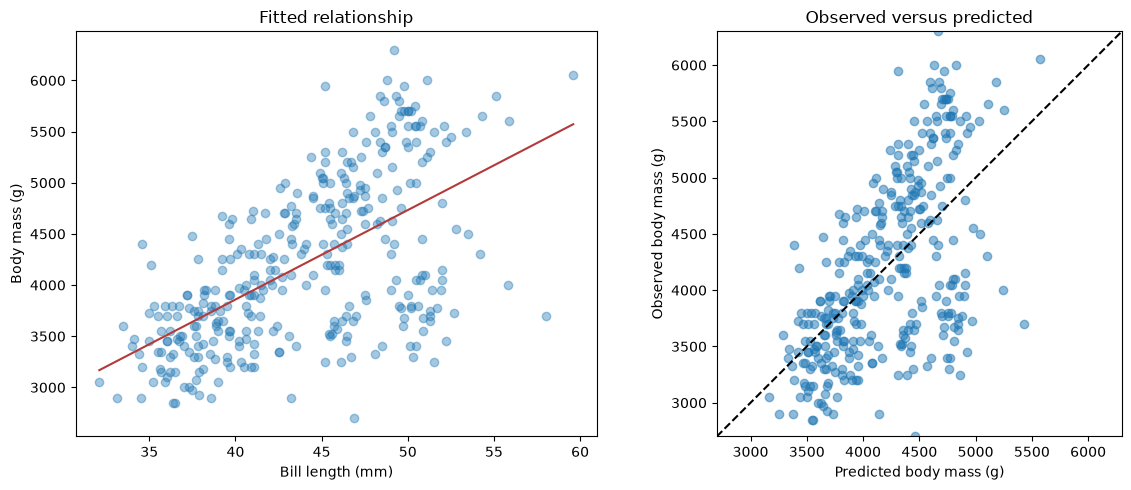

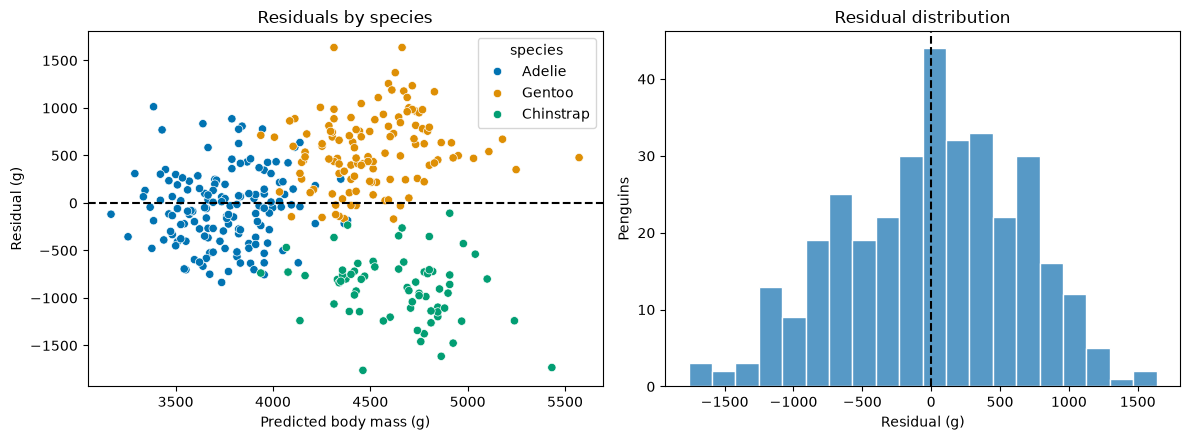

MAE (g)      521.832739
RMSE (g)     643.543338
R-squared      0.354156
dtype: float64
 quantity  statsmodels  scikit-learn  absolute_difference
intercept   362.306722    362.306722         2.899014e-12
    slope    87.415277     87.415277         9.947598e-14
R-squared     0.354156      0.354156         2.220446e-16
Predictions match: True


In [15]:
practice_data = penguins.loc[:, ["bill_length_mm", "body_mass_g", "species"]].dropna(
    subset=["bill_length_mm", "body_mass_g"]
)
X_practice = practice_data[["bill_length_mm"]]
y_practice = practice_data["body_mass_g"]
print("X shape:", X_practice.shape, "y shape:", y_practice.shape)

practice_model = LinearRegression()
practice_model.fit(X_practice, y_practice)
print("Intercept:", practice_model.intercept_)
print("Slope:", practice_model.coef_[0])

practice_predicted = practice_model.predict(X_practice)
practice_results = practice_data.assign(
    predicted_body_mass_g=practice_predicted,
    residual_g=y_practice - practice_predicted,
)

practice_line = pd.DataFrame({
    "bill_length_mm": np.linspace(X_practice.bill_length_mm.min(), X_practice.bill_length_mm.max(), 100)
})
practice_line["prediction"] = practice_model.predict(practice_line)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_practice.bill_length_mm, y_practice, alpha=0.4)
axes[0].plot(practice_line.bill_length_mm, practice_line.prediction, color="#B33A3A")
axes[0].set(title="Fitted relationship", xlabel="Bill length (mm)", ylabel="Body mass (g)")
lo = min(practice_predicted.min(), y_practice.min())
hi = max(practice_predicted.max(), y_practice.max())
axes[1].scatter(practice_predicted, y_practice, alpha=0.5)
axes[1].plot([lo, hi], [lo, hi], "k--")
axes[1].set_xlim(lo, hi)
axes[1].set_ylim(lo, hi)
axes[1].set_aspect("equal", adjustable="box")
axes[1].set(title="Observed versus predicted", xlabel="Predicted body mass (g)", ylabel="Observed body mass (g)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=practice_results, x="predicted_body_mass_g", y="residual_g",
                hue="species", palette="colorblind", ax=axes[0])
axes[0].axhline(0, color="black", ls="--")
axes[0].set(title="Residuals by species", xlabel="Predicted body mass (g)", ylabel="Residual (g)")
sns.histplot(data=practice_results, x="residual_g", bins=20, edgecolor="white", ax=axes[1])
axes[1].axvline(0, color="black", ls="--")
axes[1].set(title="Residual distribution", xlabel="Residual (g)", ylabel="Penguins")
fig.tight_layout()
plt.show()

practice_mae = mean_absolute_error(y_practice, practice_predicted)
practice_rmse = mean_squared_error(y_practice, practice_predicted) ** 0.5
practice_r2 = r2_score(y_practice, practice_predicted)
print(pd.Series({"MAE (g)": practice_mae, "RMSE (g)": practice_rmse, "R-squared": practice_r2}))

practice_sm = smf.ols("body_mass_g ~ bill_length_mm", data=practice_data).fit()
practice_comparison = pd.DataFrame({
    "quantity": ["intercept", "slope", "R-squared"],
    "statsmodels": [practice_sm.params["Intercept"], practice_sm.params["bill_length_mm"], practice_sm.rsquared],
    "scikit-learn": [practice_model.intercept_, practice_model.coef_[0], practice_r2],
})
practice_comparison["absolute_difference"] = (
    practice_comparison["statsmodels"] - practice_comparison["scikit-learn"]
).abs()
print(practice_comparison.to_string(index=False))
print("Predictions match:", np.allclose(practice_sm.predict(practice_data), practice_predicted))


**Answer:** The equation is predicted body mass = 362.31 + 87.42 times bill length. For each additional millimeter of bill length, the model predicts about 87.42 grams more body mass. The intercept represents a penguin with a zero-length bill, which is outside the observed range and is not useful in practice.

The in-sample MAE is about 521.83 grams, meaning predictions differ from actual body mass by that amount on average. The RMSE is about 643.54 grams; its higher value suggests some larger prediction errors. The R-squared is about 0.354, so the model explains about 35.4% of the variation in body mass in these data.

Statsmodels and scikit-learn give essentially the same coefficients and R-squared, and `np.allclose` returns `True` for their predictions. Both models use the same prepared rows.

The residual plot shows that Chinstrap penguins tend to have negative residuals, while Gentoo penguins tend to have positive residuals. This means the model tends to overestimate Chinstrap body mass and underestimate Gentoo body mass. Bill length alone does not capture these species differences. We still need held-out data to evaluate how well the model predicts new penguins, because these metrics use the same data used to fit the model.

## Submission check
- Complete Questions 1-10 and add your name/date.
- Restart and run all cells; verify dimensions, units, reference lines, and in-sample language.
- Confirm both packages use identical prepared rows.
- Export to HTML, open it, and submit as directed in Canvas.